# Hari 1 — Analisis, Pemodelan ML, dan Ekspor Data untuk Frontend

Notebook ini melanjutkan `pipeline_transformation.ipynb`. Input: `datasets/transformed/*.csv` dan `datasets/sedac_global_grid_lookup.json`.
Output: file JSON statis di `datasets/exports/` yang langsung dikonsumsi frontend (Hari 2).

| Bagian | Isi | Output |
|---|---|---|
| 1 | Load & audit konsistensi angka vs blueprint | - |
| 2 | Clue 1: Tren per dekade + bias Antarktika | `trend_decades.json` |
| 3 | Clue 2: Statistik 4 kelas material | `material_classes.json` |
| 4 | Clue 3a: K-Means (k=5) | `clusters.json` |
| 5 | Clue 3b: Random Forest (prediksi Fell vs Found) | `rf_model.json` |
| 6 | Mode 2: 511 pin + 19 meteorit Indonesia + fireball | `map_pins.json`, `indonesia.json`, `fireballs.json` |
| 7 | Mode 3: fisika simulator, lookup populasi, preset asteroid | `physics.json`, `city_presets.json`, `asteroid_presets.json`, `population_grid.json` |
| 8 | Manifest & verifikasi | `manifest.json` |

In [1]:
import json, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score, confusion_matrix
warnings.filterwarnings("ignore")

SEED = 42
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATASETS = PROJECT_ROOT / "datasets"
TRANSFORMED = DATASETS / "transformed"
EXPORT = DATASETS / "exports"
EXPORT.mkdir(exist_ok=True)

def clean(o):
    """Konversi tipe numpy/NaN agar aman untuk JSON."""
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)):
        return None if (math.isnan(o) or math.isinf(o)) else float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o

def save_json(name, obj):
    p = EXPORT / name
    with open(p, "w", encoding="utf-8") as f:
        json.dump(clean(obj), f, ensure_ascii=False, separators=(",", ":"), allow_nan=False)
    print(f"saved {p.relative_to(PROJECT_ROOT)}  ({p.stat().st_size/1024:.1f} KB)")

## 1. Load & audit konsistensi

In [2]:
df = pd.read_csv(TRANSFORMED / "meteorites_cleaned_transformed.csv")
df["is_antarctica"] = df["latitude"] < -60
print(df.shape)
assert len(df) == 31911

# Angka di blueprint vs data aktual
blueprint = {"Ordinary Chondrite": 28957, "Iron / Stony-Iron": 1113, "Carbonaceous Chondrite": 1219, "Achondrite": 622}
actual = df["material_class"].value_counts()
audit = pd.DataFrame({"blueprint": pd.Series(blueprint), "data_aktual": actual})
audit["selisih"] = audit["data_aktual"] - audit["blueprint"]
display(audit)
print("Outlier massa >35 kg :", int(df.is_massive_outlier.sum()), "(blueprint: 580)")
print("Proporsi Antarktika  :", f"{df.is_antarctica.mean()*100:.2f}%", "(blueprint: 72,01% dari klaster Antarktika)")

(31911, 21)


,blueprint,data_aktual,selisih
Achondrite,622,985,363
Carbonaceous Chondrite,1219,825,-394
Iron / Stony-Iron,1113,1113,0
Ordinary Chondrite,28957,28988,31


Outlier massa >35 kg : 576 (blueprint: 580)
Proporsi Antarktika  : 69.25% (blueprint: 72,01% dari klaster Antarktika)


**Catatan rekonsiliasi.** Angka kelas material di blueprint (Achondrite 622, Carbonaceous 1.219) berbeda dari hasil pemetaan `recclass` di pipeline saat ini. Sumber kebenaran untuk frontend adalah **data aktual di notebook ini**; semua angka di UI dan slide dihasilkan dari JSON ekspor, sehingga tidak ada angka hardcode yang bisa menyimpang.

## 2. Clue 1 — The 1970s Mystery Surge

,decade,total,fell,antarctica,found,non_antarctica,antarctica_pct
0,1900,136,55,0,81,136,0.00
1,1910,151,65,1,86,150,0.66
2,1920,157,68,0,89,157,0.00
3,1930,298,88,0,210,298,0.00
4,1940,188,55,0,133,188,0.00
5,1950,201,58,0,143,201,0.00
6,1960,375,57,12,318,363,3.20
7,1970,4954,57,4396,4897,558,88.74
8,1980,6801,54,6364,6747,437,93.57
9,1990,9061,54,6772,9007,2289,74.74


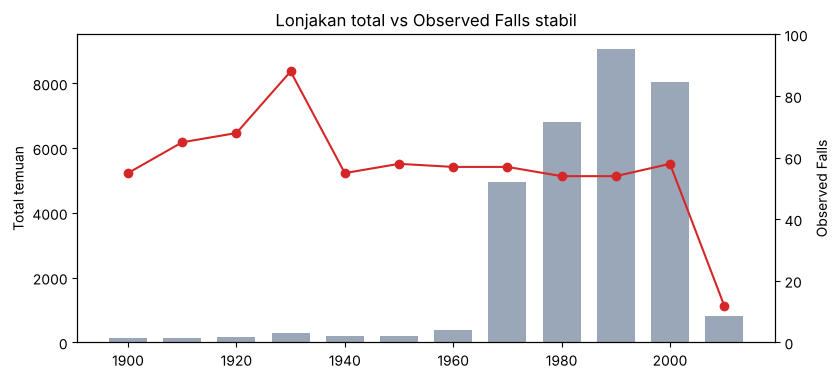

Observed Falls per dekade (1900-2000an): 54-88


In [3]:
dec = df[(df.decade >= 1900) & (df.decade <= 2010)].groupby("decade").agg(
    total=("id", "size"),
    fell=("is_fell", "sum"),
    antarctica=("is_antarctica", "sum"),
).reset_index()
dec["found"] = dec["total"] - dec["fell"]
dec["non_antarctica"] = dec["total"] - dec["antarctica"]
dec["antarctica_pct"] = (dec["antarctica"] / dec["total"] * 100).round(2)
display(dec)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(dec.decade, dec.total, width=7, color="#9aa7b8", label="Total temuan (bar)")
ax.set_ylabel("Total temuan")
ax2 = ax.twinx()
ax2.plot(dec.decade, dec.fell, color="#d62728", marker="o", label="Observed Falls (garis)")
ax2.set_ylabel("Observed Falls"); ax2.set_ylim(0, 100)
ax.set_title("Lonjakan total vs Observed Falls stabil"); plt.show()

fell_min, fell_max = int(dec.fell.min()), int(dec.fell.max())
print(f"Observed Falls per dekade (1900-2000an): {dec[dec.decade<=2000].fell.min()}-{dec[dec.decade<=2000].fell.max()}")

In [4]:
d19, d199 = dec.loc[dec.decade == 1900, "total"].iloc[0], dec.loc[dec.decade == 1990, "total"].iloc[0]
print(f"Dekade 1900: {d19}  ->  Dekade 1990: {d199}  ({d199/d19:.1f}x)")
save_json("trend_decades.json", {
    "decades": dec.to_dict("records"),
    "headline": {"decade_1900_total": d19, "decade_1990_total": d199, "ratio": round(d199 / d19, 1)},
    "note": "total = semua temuan bersih; fell = jatuhan yang teramati manusia; antarctica = lintang < -60",
})

Dekade 1900: 136  ->  Dekade 1990: 9061  (66.6x)
saved datasets/exports/trend_decades.json  (1.5 KB)


## 3. Clue 2 — Heavy Metal vs Space Pebbles

In [5]:
ANALOGY = {  # analogi sehari-hari untuk massa rata-rata (blueprint)
    "Iron / Stony-Iron": "Seberat Grand Piano",
    "Achondrite": "Seberat Bola Bowling",
    "Carbonaceous Chondrite": "Seberat Kucing Rumahan",
    "Ordinary Chondrite": "Seberat Laptop",
}
g = df.groupby("material_class")
mat = pd.DataFrame({
    "count": g.size(),
    "pct": (g.size() / len(df) * 100).round(2),
    "mean_mass_kg": g["mass_kg"].mean().round(2),
    "median_mass_g": g["mass_g"].median().round(2),
    "fell_ratio_pct": (g["is_fell"].mean() * 100).round(2),
    "density_g_cm3": g["density_g_cm3"].first(),
    "yield_strength_mpa": g["yield_strength_mpa"].first(),
    "impact_regime": g["impact_regime"].first(),
}).reset_index()
mat["analogy"] = mat["material_class"].map(ANALOGY)
mat = mat.sort_values("mean_mass_kg", ascending=False).reset_index(drop=True)
display(mat)

iron = mat.loc[mat.material_class == "Iron / Stony-Iron", "mean_mass_kg"].iloc[0]
oc = mat.loc[mat.material_class == "Ordinary Chondrite", "mean_mass_kg"].iloc[0]
print(f"Besi vs Ordinary Chondrite: {iron/oc:.0f}x lebih berat (rata-rata)")
save_json("material_classes.json", {"classes": mat.to_dict("records"), "iron_vs_ordinary_ratio": round(iron / oc)})

,material_class,count,pct,mean_mass_kg,median_mass_g,fell_ratio_pct,density_g_cm3,yield_strength_mpa,impact_regime,analogy
0,Iron / Stony-Iron,1113,3.49,478.04,9350.00,5.30,7.8,350.0,Surface Crater Impact,Seberat Grand Piano
1,Achondrite,985,3.09,5.62,65.31,8.22,3.2,65.0,Mid-Atmosphere Breakup (15-25 km),Seberat Bola Bowling
2,Carbonaceous Chondrite,825,2.59,3.90,28.00,5.33,2.2,5.0,High-Altitude Airburst (>35 km),Seberat Kucing Rumahan
3,Ordinary Chondrite,28988,90.84,1.77,26.20,3.04,3.4,35.0,Tropospheric Shockwave Airburst (15-30 km),Seberat Laptop


Besi vs Ordinary Chondrite: 270x lebih berat (rata-rata)
saved datasets/exports/material_classes.json  (1.0 KB)


## 4. Clue 3a — K-Means Spatial-Mass (k = 5)

Fitur: koordinat **3D pada bola satuan** (x, y, z) + `log10_mass_g`, distandarisasi. Memakai (x,y,z) bukan lat/lon mentah agar titik di dekat garis bujur ±180° tidak terpisah secara artifisial.

In [6]:
lat_r, lon_r = np.radians(df.latitude.values), np.radians(df.longitude.values)
X_geo = np.c_[np.cos(lat_r) * np.cos(lon_r), np.cos(lat_r) * np.sin(lon_r), np.sin(lat_r)]
X_km = np.c_[X_geo, df.log10_mass_g.values]
Xs = StandardScaler().fit_transform(X_km)

km = KMeans(n_clusters=5, n_init=20, random_state=SEED).fit(Xs)
df["cluster_raw"] = km.labels_
# urutkan ID klaster berdasarkan jumlah (besar -> kecil) agar stabil dan mudah dibaca
order = df["cluster_raw"].value_counts().index.tolist()
df["cluster"] = df["cluster_raw"].map({old: new for new, old in enumerate(order)})

rows = []
for cid in range(5):
    s = df[df.cluster == cid]
    rows.append({"cluster": cid, "count": len(s), "pct": round(len(s)/len(df)*100, 2),
                 "centroid_lat": round(s.latitude.mean(), 2), "centroid_lon": round(s.longitude.mean(), 2),
                 "lat_min": s.latitude.min(), "lat_max": s.latitude.max(),
                 "median_mass_g": round(s.mass_g.median(), 2),
                 "fell_pct": round(s.is_fell.mean()*100, 2),
                 "antarctica_pct": round(s.is_antarctica.mean()*100, 2),
                 "top_material": s.material_class.mode().iloc[0]})
cl = pd.DataFrame(rows)
display(cl)

,cluster,count,pct,centroid_lat,centroid_lon,lat_min,lat_max,median_mass_g,fell_pct,antarctica_pct,top_material
0,0,12791,40.08,-76.28,96.74,-86.93333,62.65316,4.79,0.02,99.44,Ordinary Chondrite
1,1,9969,31.24,-75.32,106.97,-87.36667,43.33333,67.00,0.31,94.07,Ordinary Chondrite
2,2,3769,11.81,19.94,58.48,-26.00000,72.68333,249.40,9.34,0.00,Ordinary Chondrite
3,3,3025,9.48,29.17,10.93,-34.10000,72.88333,365.00,14.84,0.00,Ordinary Chondrite
4,4,2357,7.39,22.48,-93.71,-57.78667,81.16667,1300.00,9.76,0.00,Ordinary Chondrite


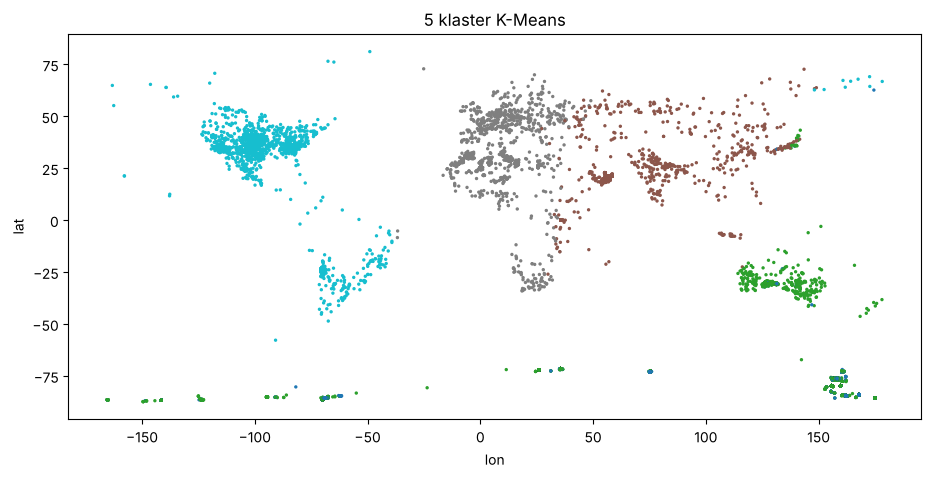

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
sc = ax.scatter(df.longitude, df.latitude, c=df.cluster, s=2, cmap="tab10")
ax.set_title("5 klaster K-Means"); ax.set_xlabel("lon"); ax.set_ylabel("lat"); plt.show()

Nama dan interpretasi klaster dibuat dari ciri hasil di atas (lintang, % Antarktika, % Fell), bukan ditebak sebelumnya.

In [8]:
def describe(r):
    if r.antarctica_pct > 90:
        return f"Antarktika (lon rata-rata {r.centroid_lon:.0f}°)", "Akumulasi sistematis hasil ekspedisi es (search bias)."
    if r.fell_pct > 10:
        return "Benua berpenduduk (global)", "Wilayah pemukiman manusia: dominasi jatuhan yang teramati (Fell)."
    if r.centroid_lat < -15 and r.centroid_lat > -40 and 100 < r.centroid_lon < 140:
        return "Gurun Australia", "Gurun datar tanpa vegetasi: meteorit mudah ditemukan."
    if abs(r.centroid_lat) < 40 and 0 < r.centroid_lon < 60:
        return "Sahara & Arab", "Gurun kering: pencarian di daratan gundul."
    if r.centroid_lat > 0 and r.centroid_lon < -30:
        return "Amerika Utara (dataran & gurun)", "Dataran/gurun AS bagian barat-tengah: banyak temuan oleh pemburu meteorit."
    return f"Wilayah ({r.centroid_lat:.0f}°, {r.centroid_lon:.0f}°)", "Wilayah campuran."
cl[["name", "interpretation"]] = cl.apply(lambda r: pd.Series(describe(r)), axis=1)
display(cl[["cluster", "name", "count", "pct", "centroid_lat", "centroid_lon", "fell_pct", "antarctica_pct", "interpretation"]])
ant_clusters = cl[cl.antarctica_pct > 50]
print("Total di klaster dominan Antarktika:", int(ant_clusters["count"].sum()), f"({ant_clusters['count'].sum()/len(df)*100:.2f}%)")
print("Total titik berlintang < -60 (Antarktika sebenarnya):", int(df.is_antarctica.sum()), f"({df.is_antarctica.mean()*100:.2f}%)")
save_json("clusters.json", {"k": 5, "features": ["x", "y", "z", "log10_mass_g"], "random_state": SEED,
    "clusters": cl.to_dict("records"),
    "antarctic_clusters_count": int(ant_clusters["count"].sum()),
    "antarctic_clusters_pct": round(ant_clusters["count"].sum()/len(df)*100, 2)})

,cluster,name,count,pct,centroid_lat,centroid_lon,fell_pct,antarctica_pct,interpretation
0,0,Antarktika (lon rata-rata 97°),12791,40.08,-76.28,96.74,0.02,99.44,Akumulasi sistematis hasil ekspedisi es (searc...
1,1,Antarktika (lon rata-rata 107°),9969,31.24,-75.32,106.97,0.31,94.07,Akumulasi sistematis hasil ekspedisi es (searc...
2,2,Sahara & Arab,3769,11.81,19.94,58.48,9.34,0.00,Gurun kering: pencarian di daratan gundul.
3,3,Benua berpenduduk (global),3025,9.48,29.17,10.93,14.84,0.00,Wilayah pemukiman manusia: dominasi jatuhan ya...
4,4,Amerika Utara (dataran & gurun),2357,7.39,22.48,-93.71,9.76,0.00,Dataran/gurun AS bagian barat-tengah: banyak t...


Total di klaster dominan Antarktika: 22760 (71.32%)
Total titik berlintang < -60 (Antarktika sebenarnya): 22097 (69.25%)
saved datasets/exports/clusters.json  (1.7 KB)


## 5. Clue 3b — Random Forest: Bisakah AI menebak "Fell" vs "Found" dari lokasi?

Target `is_fell` (1 = jatuhan teramati). Data sangat **tidak seimbang** (~3% Fell), sehingga *accuracy* saja menyesatkan: model yang selalu menebak "Found" sudah ~97%. Karena itu dilaporkan juga **ROC-AUC, PR-AUC, dan balanced accuracy**, plus baseline.

In [9]:
mat_dummies = pd.get_dummies(df["material_class"], prefix="mat")
feat = pd.concat([df[["abs_latitude", "latitude", "log10_mass_g", "longitude"]], mat_dummies], axis=1)
y = df["is_fell"].values
Xtr, Xte, ytr, yte = train_test_split(feat, y, test_size=0.2, stratify=y, random_state=SEED)

rf = RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_leaf=2,
                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
proba = rf.predict_proba(Xte)[:, 1]
pred = (proba >= 0.5).astype(int)

baseline_acc = 1 - yte.mean()
metrics = {
    "accuracy": accuracy_score(yte, pred),
    "baseline_accuracy_always_found": baseline_acc,
    "balanced_accuracy": balanced_accuracy_score(yte, pred),
    "roc_auc": roc_auc_score(yte, proba),
    "pr_auc": average_precision_score(yte, proba),
    "fell_share_test": yte.mean(),
    "n_train": len(ytr), "n_test": len(yte),
}
for k, v in metrics.items(): print(f"{k:32s}: {v:.4f}" if isinstance(v, float) else f"{k:32s}: {v}")
tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
print("confusion (tn, fp, fn, tp):", tn, fp, fn, tp)

accuracy                        : 0.9861
baseline_accuracy_always_found  : 0.9666
balanced_accuracy               : 0.9112
roc_auc                         : 0.9946
pr_auc                          : 0.8541
fell_share_test                 : 0.0334
n_train                         : 25528
n_test                          : 6383
confusion (tn, fp, fn, tp): 6117 53 36 177


,feature,label,importance_pct
0,abs_latitude,Absolute Latitude (|lintang|),30.06
1,latitude,Latitude,29.88
2,log10_mass_g,Log10 Mass,21.86
3,longitude,Longitude,16.69
4,mat_Iron / Stony-Iron,Komposisi Iron/Stony-Iron,0.59
5,mat_Ordinary Chondrite,Komposisi Ordinary Chondrite,0.46
6,mat_Achondrite,Komposisi Achondrite,0.34
7,mat_Carbonaceous Chondrite,Komposisi Carbonaceous Chondrite,0.11


Total pengaruh garis lintang: 59.95%


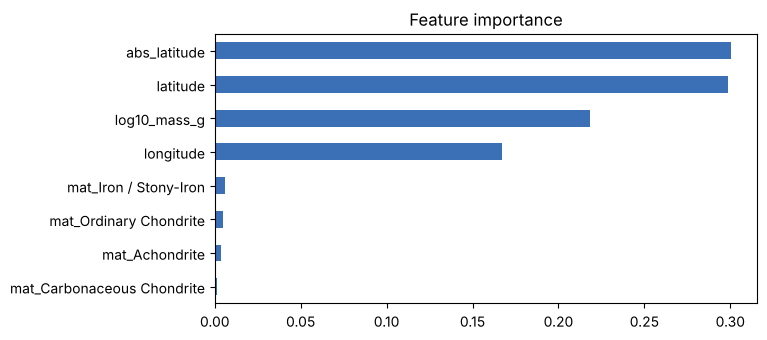

saved datasets/exports/rf_model.json  (1.0 KB)


In [10]:
imp = pd.Series(rf.feature_importances_, index=feat.columns).sort_values(ascending=False)
LABELS = {"abs_latitude": "Absolute Latitude (|lintang|)", "latitude": "Latitude", "log10_mass_g": "Log10 Mass",
          "longitude": "Longitude", "mat_Iron / Stony-Iron": "Komposisi Iron/Stony-Iron",
          "mat_Ordinary Chondrite": "Komposisi Ordinary Chondrite", "mat_Achondrite": "Komposisi Achondrite",
          "mat_Carbonaceous Chondrite": "Komposisi Carbonaceous Chondrite"}
imp_df = pd.DataFrame({"feature": imp.index, "label": [LABELS.get(i, i) for i in imp.index], "importance_pct": (imp.values*100).round(2)})
display(imp_df)
geo = imp[["abs_latitude", "latitude"]].sum() * 100
print(f"Total pengaruh garis lintang: {geo:.2f}%")
imp.sort_values().plot.barh(figsize=(7, 3.5), color="#3b6fb6"); plt.title("Feature importance"); plt.show()
save_json("rf_model.json", {"target": "is_fell", "metrics": metrics,
    "confusion": {"tn": tn, "fp": fp, "fn": fn, "tp": tp},
    "feature_importance": imp_df.to_dict("records"), "latitude_total_pct": round(geo, 2)})

## 6. Mode 2 — Treasure Map

- **511 pin** = 150 meteorit terberat dunia + 361 sampel berstrata per klaster K-Means (reproducible, `random_state=42`).
- Titik Antarktika (lintang < −60) diberi *coordinate jitter* ±0,15° agar tidak menumpuk di satu piksel.
- 19 meteorit Indonesia = katalog terpisah (filter khusus).
- Fireball CNEOS = lapisan satelit (bola api atmosferik).

In [11]:
rng = np.random.default_rng(SEED)
top150 = df.sort_values("mass_g", ascending=False).head(150)
rest = df.drop(top150.index)
per = [361 // 5 + (1 if i < 361 % 5 else 0) for i in range(5)]
strat = pd.concat([rest[rest.cluster == c].sample(n=per[c], random_state=SEED) for c in range(5)])
pins = pd.concat([top150.assign(pin_source="heaviest"), strat.assign(pin_source="stratified")])
assert len(pins) == 511 and pins.id.is_unique

jit = pins.is_antarctica.values
pins["map_lat"] = pins.latitude.values + np.where(jit, rng.uniform(-0.15, 0.15, len(pins)), 0)
pins["map_lon"] = pins.longitude.values + np.where(jit, rng.uniform(-0.15, 0.15, len(pins)), 0)
print(pins.pin_source.value_counts().to_dict(), "| jitter pada", int(jit.sum()), "pin Antarktika")

cols = ["id", "name", "recclass", "material_class", "year", "fall_type", "mass_kg", "latitude", "longitude", "map_lat", "map_lon", "cluster", "pin_source"]
out = pins[cols].copy()
out["mass_kg"] = out.mass_kg.round(3)
out[["map_lat", "map_lon"]] = out[["map_lat", "map_lon"]].round(5)
save_json("map_pins.json", {"count": len(out), "pins": out.to_dict("records")})

{'stratified': 361, 'heaviest': 150} | jitter pada 141 pin Antarktika
saved datasets/exports/map_pins.json  (128.3 KB)


In [12]:
idn = pd.read_csv(TRANSFORMED / "indonesia_meteorites_transformed.csv")
idn = idn.sort_values("mass_kg", ascending=False).reset_index(drop=True)
idn["is_default_pin"] = idn.name.eq("Prambanan")
display(idn[["name", "year", "recclass", "mass_kg", "fall_type", "energy_tons_tnt"]])
assert len(idn) == 19
save_json("indonesia.json", {"count": len(idn), "default_pin": "Prambanan",
    "meteorites": idn[["name", "id", "recclass", "material_class", "year", "fall_type", "mass_kg", "latitude", "longitude",
                       "energy_tons_tnt", "impact_regime", "is_default_pin"]].to_dict("records")})

,name,year,recclass,mass_kg,fall_type,energy_tons_tnt
0,Prambanan,1797.0,"Iron, ungrouped",500.000,Found,17.27
1,Jepara,2008.0,"Pallasite, PMG",499.500,Found,17.25
2,Djati-Pengilon,1884.0,H6,166.000,Fell,5.73
3,Jumapalo,1984.0,L6,32.490,Fell,1.12
4,Meester-Cornelis,1915.0,H5,24.750,Fell,0.85
5,Tjabe,1869.0,H6,20.000,Fell,0.69
6,Tjerebon,1922.0,L5,16.500,Fell,0.57
7,Bandong,1871.0,LL6,11.500,Fell,0.40
8,Tambakwatu,1975.0,L6,10.500,Fell,0.36
9,Rembang,1919.0,"Iron, IVA",10.000,Fell,0.35


saved datasets/exports/indonesia.json  (5.2 KB)


In [13]:
fb = pd.read_csv(TRANSFORMED / "cneos_fireballs_transformed.csv").dropna(subset=["latitude", "longitude"])
print(len(fb), "fireball | energi maks (kt):", fb.energy_kilotons_tnt.max(), "| rentang:", fb.datetime_utc.min(), "->", fb.datetime_utc.max())
def pick(prefix):
    r = fb[fb.datetime_utc.str.startswith(prefix)].sort_values("energy_kilotons_tnt", ascending=False).iloc[0]
    return {"latitude": r.latitude, "longitude": r.longitude, "energy_kilotons_tnt": r.energy_kilotons_tnt,
            "altitude_km": r.altitude_km, "datetime_utc": r.datetime_utc}
special = [{"name": "Chelyabinsk (Rusia)", "note": "Airburst; ~1.500 luka akibat pecahan kaca", **pick("2013-02-15")},
           {"name": "Bolide Bone (Sulawesi)", "note": "Blueprint menulis ~50 kt; CNEOS mencatat nilai di bawah", **pick("2009-10-08")}]
print(special)
save_json("fireballs.json", {"count": len(fb), "fireballs": fb.round(3).to_dict("records"), "special_cases": special})

888 fireball | energi maks (kt): 441.0 | rentang: 1988-04-15 03:03:10 -> 2026-10-04 03:14:45
[{'name': 'Chelyabinsk (Rusia)', 'note': 'Airburst; ~1.500 luka akibat pecahan kaca', 'latitude': np.float64(54.8), 'longitude': np.float64(61.1), 'energy_kilotons_tnt': np.float64(441.0), 'altitude_km': np.float64(23.3), 'datetime_utc': '2013-02-15 03:20:26'}, {'name': 'Bolide Bone (Sulawesi)', 'note': 'Blueprint menulis ~50 kt; CNEOS mencatat nilai di bawah', 'latitude': np.float64(-4.2), 'longitude': np.float64(120.6), 'energy_kilotons_tnt': np.float64(33.0), 'altitude_km': np.float64(19.1), 'datetime_utc': '2009-10-08 02:57:14'}]


saved datasets/exports/fireballs.json  (130.2 KB)


> Kasus khusus Chelyabinsk (2013) dan Bolide Bone (2009) diambil langsung dari data CNEOS. Energi Bone di CNEOS **33 kt**, bukan ~50 kt seperti di blueprint; pakai angka CNEOS di UI dan slide atau perbarui blueprint.

## 7. Mode 3 — Fisika simulator, populasi, dan preset asteroid

Rumus mengikuti blueprint. Fungsi didefinisikan di sini sebagai **referensi implementasi** untuk JavaScript di Hari 2 dan diverifikasi dengan contoh Jumapalo.

In [14]:
TNT_J = 4.184e9
def impact(mass_kg, v_ms=17000.0):
    E = 0.5 * mass_kg * v_ms**2
    kt = E / TNT_J / 1000
    return {"energy_joules": E, "energy_tons_tnt": E / TNT_J, "energy_kilotons": kt,
            "r_crater_m": 15 * kt ** (1/3), "r_blast_m": 220 * kt ** (1/3), "r_glass_m": 650 * kt ** (1/3)}
def dart_shift_km(delta_v_ms, lead_time_s): return delta_v_ms * lead_time_s / 1000

j = impact(32.49)
print({k: round(v, 4) for k, v in j.items()})
shift = dart_shift_km(0.01, 30 * 86400)
print("Pergeseran DART (1 cm/s, 30 hari):", round(shift, 2), "km")
assert abs(j["energy_joules"] - 4.69e9) / 4.69e9 < 0.01 and abs(j["energy_tons_tnt"] - 1.12) < 0.01
assert abs(shift - 25.92) < 0.01
print("Verifikasi Jumapalo & DART sesuai blueprint: OK")
assert round(j["r_glass_m"]) == 68

{'energy_joules': 4694805000.0, 'energy_tons_tnt': 1.1221, 'energy_kilotons': 0.0011, 'r_crater_m': 1.5587, 'r_blast_m': 22.8611, 'r_glass_m': 67.5443}
Pergeseran DART (1 cm/s, 30 hari): 25.92 km
Verifikasi Jumapalo & DART sesuai blueprint: OK


**Hasil verifikasi.** Jumapalo: energi 4,69e9 J, 1,12 ton TNT, R_glass ≈ 67,5 m (≈ 68 m) dan pergeseran DART 25,92 km semuanya cocok dengan blueprint. Satu hal belum punya rumus: **breakup altitude 19,9 km** tidak diturunkan dari persamaan apa pun di blueprint. Rumus yield-strength standar menghasilkan angka berbeda, jadi tentukan rumusnya di Hari 2 atau jangan tampilkan angka itu.

In [15]:
# Lookup populasi dari grid GPWv4 0.5 derajat
with open(DATASETS / "sedac_global_grid_lookup.json") as f:
    grid = json.load(f)
cells = np.array(grid["cells"], dtype=float)  # [lat, lon, density_km2], sel = pusat 0.5°
print("sel berpenghuni:", len(cells), "| format:", grid["format"])
R_EARTH = 6371.0088
def pop_within(lat, lon, radius_m):
    """Estimasi populasi dalam lingkaran radius_m. Sel dihitung penuh jika pusatnya dalam radius. Resolusi 0,5° (~55 km): kasar untuk radius kecil."""
    r_km = radius_m / 1000
    p1, p2 = np.radians(lat), np.radians(cells[:, 0])
    dl = np.radians(cells[:, 1] - lon)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    d = 2 * R_EARTH * np.arcsin(np.sqrt(a))
    m = d <= r_km
    area = (111.32 * 0.5) * (111.32 * 0.5) * np.cos(p2[m])
    return float((cells[m, 2] * area).sum())
def density_at(lat, lon):
    i = np.argmin((cells[:, 0] - lat) ** 2 + ((cells[:, 1] - lon + 180) % 360 - 180) ** 2)
    ok = abs(cells[i, 0] - lat) <= 0.25 and abs((cells[i, 1] - lon + 180) % 360 - 180) <= 0.25
    return float(cells[i, 2]) if ok else 0.0

print("Jakarta radius 50 km :", round(pop_within(-6.2, 106.85, 50_000)))
print("Jakarta radius 150 km:", round(pop_within(-6.2, 106.85, 150_000)))
print("Samudra Pasifik 50 km:", round(pop_within(-30, -140, 50_000)))

sel berpenghuni: 46704 | format: [lat, lon, pop_density_km2]
Jakarta radius 50 km : 20544817
Jakarta radius 150 km: 97514602
Samudra Pasifik 50 km: 0


**Keterbatasan penting.** Grid 0,5° (~55 km) terlalu kasar untuk radius cincin dari meteorit kecil (puluhan–ratusan meter): hasilnya akan 0 atau melonjak ke satu sel penuh. Untuk skenario tersebut frontend sebaiknya memakai **kepadatan titik** (`density_at`) × luas lingkaran, dan memakai `pop_within` hanya bila radius > ~50 km. Bagian ini yang sebaiknya diputuskan di Hari 2.

In [16]:
CITIES = [("Jakarta", -6.2, 106.85, "ID"), ("Surabaya", -7.25, 112.75, "ID"), ("Yogyakarta", -7.8, 110.37, "ID"),
          ("Medan", 3.59, 98.67, "ID"), ("Makassar", -5.15, 119.43, "ID"), ("Denpasar", -8.65, 115.22, "ID"),
          ("Manado", 1.47, 124.84, "ID"), ("Tokyo", 35.68, 139.69, "JP"), ("New York", 40.71, -74.0, "US"),
          ("London", 51.51, -0.13, "GB"), ("Mumbai", 19.08, 72.88, "IN"), ("Cairo", 30.04, 31.24, "EG"),
          ("Sao Paulo", -23.55, -46.63, "BR"), ("Lagos", 6.52, 3.38, "NG"), ("Sydney", -33.87, 151.21, "AU"),
          ("Chelyabinsk", 55.16, 61.43, "RU")]
city_rows = [{"name": n, "latitude": la, "longitude": lo, "country": c, "density_km2": density_at(la, lo),
              "pop_50km": round(pop_within(la, lo, 50_000)), "pop_150km": round(pop_within(la, lo, 150_000))} for n, la, lo, c in CITIES]
display(pd.DataFrame(city_rows))
save_json("city_presets.json", {"cities": city_rows})

,name,latitude,longitude,country,density_km2,pop_50km,pop_150km
0,Jakarta,-6.20,106.85,ID,2229.3,20544817,97514602
1,Surabaya,-7.25,112.75,ID,2842.9,17175454,53923105
2,Yogyakarta,-7.80,110.37,ID,1137.1,10522066,54695599
3,Medan,3.59,98.67,ID,1764.5,7206211,19492692
4,Makassar,-5.15,119.43,ID,247.0,2127489,24101396
5,Denpasar,-8.65,115.22,ID,665.9,11690578,27799877
6,Manado,1.47,124.84,ID,339.8,3441977,9883883
7,Tokyo,35.68,139.69,JP,8299.6,27722277,62422146
8,New York,40.71,-74.00,US,5111.6,22571660,39565900
9,London,51.51,-0.13,GB,957.3,7991426,41677841


saved datasets/exports/city_presets.json  (2.0 KB)


In [17]:
neo = pd.read_csv(TRANSFORMED / "neows_asteroids_transformed.csv")
cad = pd.read_csv(TRANSFORMED / "cad_approaches_transformed.csv")
sen = pd.read_csv(TRANSFORMED / "sentry_risks_transformed.csv")

def rough_mass_kg(d_km, rho=2600):  # bola homogen, densitas asumsi 2600 kg/m3
    r = d_km * 1000 / 2
    return 4/3 * math.pi * r**3 * rho

neo["diameter_mean_m"] = (neo.diameter_min_km + neo.diameter_max_km) / 2 * 1000
neo["mass_kg_est"] = neo.diameter_mean_m.apply(lambda m: rough_mass_kg(m/1000))
neo_out = neo.sort_values("diameter_mean_m", ascending=False)[["neo_id", "name", "diameter_mean_m", "mass_kg_est", "velocity_kms",
        "distance_ld", "is_potentially_hazardous", "is_sentry_object", "datetime_utc"]].round(4)

sen["diameter_m"] = sen.diameter_km * 1000
sen_out = sen.sort_values("palermo_scale_max", ascending=False).head(25)[["designation", "fullname", "impact_probability", "diameter_m",
        "palermo_scale_max", "torino_scale_max", "velocity_inf_kms", "year_range"]]
sen_out["mass_kg_est"] = sen_out.diameter_m.apply(lambda m: rough_mass_kg(m/1000) if pd.notna(m) else None)

cad_out = cad.sort_values("distance_ld").head(25)[["designation", "datetime_utc", "distance_ld", "velocity_rel_kms", "absolute_magnitude_h"]]
display(neo_out.head(5)); display(sen_out.head(5)); display(cad_out.head(5))
save_json("asteroid_presets.json", {
    "mass_note": "mass_kg_est = bola homogen, densitas 2600 kg/m3 (asumsi kasar) dari diameter",
    "neows_feed": neo_out.to_dict("records"), "sentry_top25": sen_out.to_dict("records"), "cad_closest25": cad_out.to_dict("records")})

,neo_id,name,diameter_mean_m,mass_kg_est,velocity_kms,distance_ld,is_potentially_hazardous,is_sentry_object,datetime_utc
27,3137852,(2002 TA69),842.4471,8.139539e+11,23.1164,34.7889,False,False,2026-10-26 06:21:00
34,3092205,(1998 WL4),543.9295,2.190785e+11,35.8095,156.8331,False,False,2026-10-25 18:41:00
26,2516803,516803 (2010 JG88),536.4665,2.101841e+11,20.4016,33.7485,False,False,2026-10-26 19:23:00
7,3159894,(2003 RL10),521.8463,1.934638e+11,14.5372,87.9695,False,False,2026-10-28 01:25:00
32,3831888,(2018 UA1),448.2730,1.226309e+11,20.4095,117.2565,True,False,2026-10-26 14:45:00


,designation,fullname,impact_probability,diameter_m,palermo_scale_max,torino_scale_max,velocity_inf_kms,year_range,mass_kg_est
81,29075,29075 (1950 DA),3.401000e-04,1300.0,-0.98,0,14.100000,2880-2880,2.990901e+12
48,101955,101955 Bennu (1999 RQ36),5.717000e-04,490.0,-1.58,0,5.991698,2178-2290,1.601623e+11
160,2008 JL3,(2008 JL3),1.658148e-04,29.0,-2.39,0,8.419012,2027-2122,3.320213e+07
0,2010 RF12,(2010 RF12),1.026373e-01,7.1,-2.96,0,5.100016,2095-2122,4.872446e+05
1412,1979 XB,(1979 XB),8.515158e-07,660.0,-2.99,0,23.760623,2056-2113,3.913846e+11


,designation,datetime_utc,distance_ld,velocity_rel_kms,absolute_magnitude_h
0,2026 TP128,2026-10-15 14:38:00,0.019484,21.489969,31.978
1,2026 PC6,2026-08-12 00:50:00,0.053245,14.046912,27.943
2,2026 RT34,2026-09-13 09:08:00,0.054540,13.076976,30.357
3,2026 SZ2,2026-09-20 21:19:00,0.055178,7.989186,30.561
4,2026 EM,2026-03-07 19:45:00,0.072104,8.186172,31.520


saved datasets/exports/asteroid_presets.json  (20.2 KB)


In [18]:
save_json("physics.json", {
    "constants": {"tnt_joules_per_ton": TNT_J, "default_velocity_ms": 17000},
    "formulas": {"energy_joules": "0.5 * mass_kg * v^2", "energy_kilotons": "joules / 4.184e9 / 1000",
                 "r_crater_m": "15 * kt^(1/3)", "r_blast_m": "220 * kt^(1/3)", "r_glass_m": "650 * kt^(1/3)",
                 "dart_shift_km": "delta_v_ms * lead_time_s / 1000"},
    "no_crater_rule": "ordinary chondrite < 500 kg meledak di udara: tampilkan Fragment Strewn Field",
    "verified_example": {"name": "Jumapalo", "mass_kg": 32.49, **j, "dart_shift_km_1cms_30d": shift},
    "material_params": mat[["material_class", "density_g_cm3", "yield_strength_mpa", "impact_regime"]].to_dict("records")})
# grid populasi disalin apa adanya supaya frontend hanya perlu membaca satu folder
save_json("population_grid.json", grid)

saved datasets/exports/physics.json  (1.2 KB)


saved datasets/exports/population_grid.json  (791.6 KB)


## 8. Manifest & verifikasi

In [19]:
import datetime
files = sorted(p for p in EXPORT.glob("*.json") if p.name != "manifest.json")
manifest = {"generated_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
            "files": {p.name: round(p.stat().st_size / 1024, 1) for p in files}}
save_json("manifest.json", manifest)
for p in files:
    with open(p, encoding="utf-8") as f: json.load(f)   # pastikan valid
print("Semua", len(files), "file JSON valid.")
print("Total:", round(sum(manifest["files"].values())/1024, 2), "MB")

saved datasets/exports/manifest.json  (0.3 KB)


Semua 11 file JSON valid.
Total: 1.06 MB
